# Observational zonal velocity

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Import data files

In [11]:
#dsW = xr.open_dataset('data/P04_1989/bottle_P04W_1989.nc')
#dsC = xr.open_dataset('data/P04_1989/bottle_P04C_1989.nc')
dsE = xr.open_dataset('data/P04_1989/bottle_P04E_1989.nc')
dHe3 = dsE.delta_helium_3.dropna(dim='N_PROF', how='all')

In [12]:
u_2026 = xr.open_dataset('data/P04_2026/crest-to-seamounts.uprof.nc')

## Mean 3-He Profile

In [13]:
MIN_PROFILE_DEPTH_M = 4600.0

# Approximate pressure in dbar as depth in metres; no conversion.
dHe3 = dsE.delta_helium_3.dropna(dim='N_PROF', how='all')
valid_samples = np.isfinite(dHe3) & np.isfinite(dHe3.pressure)
max_sample_depth_m = dHe3.pressure.where(valid_samples).max(dim='N_LEVELS')
dHe3 = dHe3.where(max_sample_depth_m >= MIN_PROFILE_DEPTH_M, drop=True)
if dHe3.sizes['N_PROF'] == 0:
    raise ValueError(f'No helium profiles reach {MIN_PROFILE_DEPTH_M:g} m')
print(f"Selected {dHe3.sizes['N_PROF']} helium profiles reaching at least {MIN_PROFILE_DEPTH_M:g} m")

Selected 4 helium profiles reaching at least 4600 m


In [14]:
# Pressure varies by profile, so interpolate each profile separately.
pressure_grid = np.arange(0.0, 7000.0, 1)
interpolated = np.full((dHe3.sizes['N_PROF'], pressure_grid.size), np.nan)
for i in range(dHe3.sizes['N_PROF']):
    profile = dHe3.isel(N_PROF=i)
    pressure = profile.pressure.values
    helium = profile.values
    valid = np.isfinite(pressure) & np.isfinite(helium)
    pressure, helium = pressure[valid], helium[valid]
    unique_pressure, inverse = np.unique(pressure, return_inverse=True)
    if unique_pressure.size < 2:
        continue
    unique_helium = np.bincount(inverse, weights=helium) / np.bincount(inverse)
    interpolated[i] = np.interp(
        pressure_grid, unique_pressure, unique_helium,
        left=np.nan, right=np.nan,
    )

profile_coords = {
    name: coord for name, coord in dHe3.coords.items()
    if set(coord.dims).issubset({'N_PROF'})
}
dHe3_interp = xr.DataArray(
    interpolated,
    dims=('N_PROF', 'pressure'),
    coords={**profile_coords, 'pressure': pressure_grid},
    name=dHe3.name,
    attrs=dHe3.attrs,
)
dHe3_interp.pressure.attrs = dict(dHe3.pressure.attrs)

In [15]:
dHe3_mean = dHe3_interp.mean(dim='N_PROF')

In [16]:
dHe3_mean.to_netcdf("data/P04_1989/dHe3_mean.nc")

## Velocity Profile

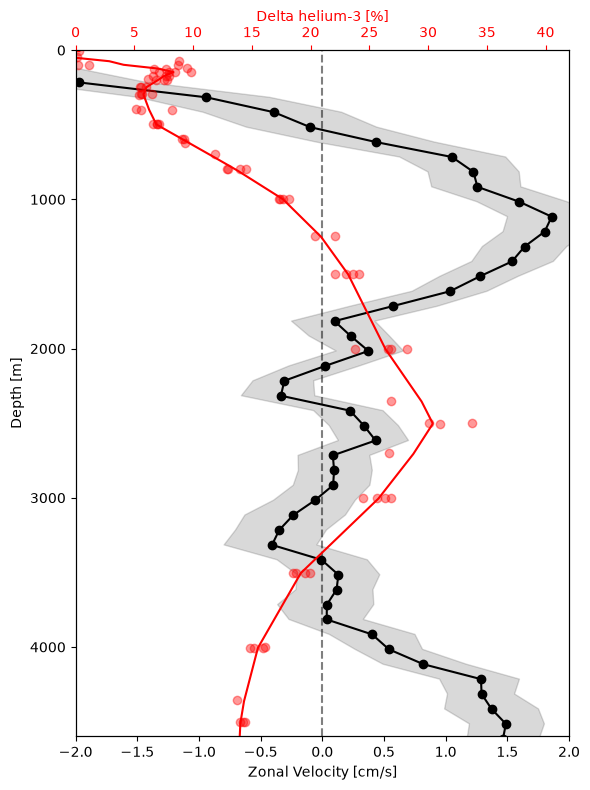

In [10]:
fig, ax = plt.subplots(figsize=(6, 8))
ax.plot(u_2026.u*100, u_2026.depth, marker='o', color='k')
ax.fill_betweenx(u_2026.depth,
                 u_2026['u.minlim']*100,
                 u_2026['u.maxlim']*100,
                 color="black",
                 alpha=0.15,
                 zorder=1)
ax_helium = ax.twiny()
ax_helium.set_xlim(0, 42)
for i in range(dHe3.sizes['N_PROF']):
    profile = dHe3.isel(N_PROF=i)
    ax_helium.plot(profile, profile.pressure, marker='o', linestyle='', color='r', alpha=0.4)
ax_helium.plot(dHe3_mean, dHe3_mean.pressure, color='r', alpha=1)
ax.axvline(0,color='k', alpha=0.5, linestyle='--')
ax.invert_yaxis()
ax.set_ylim(4600, 0)
ax.set_xlim(-2, 2)
ax.set_xlabel('Zonal Velocity [cm/s]')
ax.set_ylabel('Depth [m]')
ax_helium.set_xlabel('Delta helium-3 [%]', color='r')
ax_helium.tick_params(axis='x', colors='r')
fig.tight_layout()
plt.show()